In [2]:
using Revise
includet("../../cluster_env/runs/si_pdes1/base.jl")
using SSMCMain.ModifiedMiCRM.FFTAnalysis

In [3]:
using ProgressMeter
using ColorSchemes
using UnPack
using Statistics

In [4]:
includet("../../scripts/figures_util.jl")

using GLMakie
using CairoMakie
CairoMakie.activate!()

# Load data

## MM dataset for Fig. 3c
(100 peaks, many systems, many ps)## MM dataset for Fig. 3c
(100 peaks, many systems, many ps)

In [5]:
mmpdes_df = load("../../cluster_env/runs/mm_pdes/main1/analyzed_df.jld2", "df");
mmpdes_md = mmpdes_df.settings[1].setup_metadata;

## Main SI dataset for Fig. 3d
(100 peaks, fewer systems, two ps, also has runs of associated MMs)

In [6]:
m8dir = "../../cluster_env/runs/si_pdes1/main8_totbiom/"

m8_setup_df = load(joinpath(m8dir, "systems.jld2"), "pde_df")
m8_smd = load(joinpath(m8dir, "systems.jld2"), "metadata")
m8_df = collect_pde_runs(joinpath(m8dir, "data"))

# extinct strains were dropped at setup, so Ns varies by system and the hss is
# carried per row in the setup file
m8_df.Ns = [get_Ns(m8_setup_df.params[i])[1] for i in m8_df.pde_df_row]
m8_df.B_hss = [sum(m8_setup_df.ode_hss[i][1:ns]) for (i, ns) in zip(m8_df.pde_df_row, m8_df.Ns)]
m8_T = m8_df.T[1]

@printf("%d/%d rows, retcodes %s\n", nrow(m8_df), nrow(m8_setup_df),
    string(sort(unique(string.(m8_df.retcode)))))
@show m8_smd.ps m8_T length(unique(m8_df.gdf_row));

40/40 rows, retcodes ["MaxTime", "Success"]
m8_smd.ps = [0.1, 1.0]
m8_T = 1.0e8
length(unique(m8_df.gdf_row)) = 20

## Main SI dataset for FIg. 3e

In [7]:
m9dir = "../../cluster_env/runs/si_pdes1/main9_commcomp/"

m9_setup_df = load(joinpath(m9dir, "systems2.jld2"), "pde_df")
m9_smd = load(joinpath(m9dir, "systems2.jld2"), "metadata")
m9_all_runs = collect_pde_runs(joinpath(m9dir, "data"))   # only the rows that have a file

# drop the runs that stopped before their T - their final state is not a converged
# one, so it has no business in a composition comparison
m9_finished = m9_all_runs.final_T .>= m9_all_runs.T
m9_runs = m9_all_runs[m9_finished, :]
@printf("excluded %d/%d runs that did not reach T = %.3g\n",
    count(.!m9_finished), nrow(m9_all_runs), m9_all_runs.T[1])

m9_df = DataFrame(map(eachrow(m9_runs)) do r
    s = m9_setup_df[r.pde_df_row, :]
    Ns, Nr = get_Ns(s.ode_params)
    (;
        sys=r.gdf_row,
        r.p,
        hss=s.ode_hss,
        pde_fs=r.final_state,
        so_hss=s.ode_hss[1:Ns],
        so_fs=vec(mean(view(r.final_state, 1:Ns, :); dims=2)),
    )
end)

@printf("%d/%d rows, retcodes %s\n", nrow(m9_df), nrow(m9_setup_df),
    string(sort(unique(string.(m9_runs.retcode)))))
@printf("strains per system: %d - %d\n", extrema(length.(m9_df.so_hss))...)

names(m9_df)

excluded 4/300 runs that did not reach T = 1e+08
296/300 rows, retcodes ["Success"]strains per system: 2 - 8

6-element Vector{String}:
 "sys"
 "p"
 "hss"
 "pde_fs"
 "so_hss"
 "so_fs"

# ecdf justifying the extinction threshold

In [49]:
si_odes_f = jldopen("../../cluster_env/runs/si_pdes1/ode_solves.jld2")
si_odes_fmd = si_odes_f["metadata"]

si_odes_df = si_odes_f["df"];
close(si_odes_f)
count(si_odes_df.good), nrow(si_odes_df)

(6256, 10000)

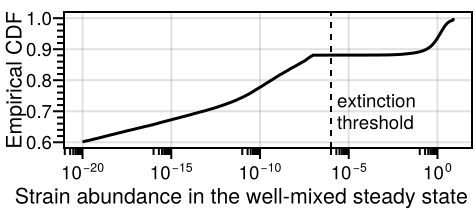

In [58]:
min_thr = 1e-20
npoints = 1000

strain_abundances = vcat(getindex.(si_odes_df.final_states, Ref(1:si_odes_fmd.N))...);
csas = clamp.(strain_abundances, min_thr, Inf)
ee = ecdf(log10.(csas))
lxs = range(log10(min_thr), log10.(maximum(csas)), npoints);
ys = ee.(lxs);

fig = Figure(;
    size=(double_col_width * 0.35, 0.25 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

ax = Axis(fig[1, 1];
    # labels
    xlabel="Strain abundance in the well-mixed steady state         ",
    ylabel="Empirical CDF",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    # setup log scale ticks with minors
    xscale=log10,
    # xticks=log10ticks(-20:5:3),
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(10),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

lines!(ax, 10 .^ lxs, ys; color=:black)
vlines!(ax, 1e-6;
    color=:black,
    linestyle=:dash,
    linewidth=1.,
)
text!(ax, 1e-6, 0.7;
    text="extinction\nthreshold",
    align=(:left, :center),
    offset=(3., 0.),
    fontsize=7fontsize_pt,
)

Makie.save("../../figures2/si_extras/strain_abundances_ext_thr.pdf", fig)

fig

# Early onset matches linstab length scale

## One figure showing both

In [8]:
mmpdes_df.linstab_l = 2pi ./ mmpdes_df.peak_k;
mmpdes_df.et_l = map(mmpdes_df.early_time_modes) do etm etm.lengthscale end;

In [11]:
m8_df.ts = Vector{Vector{Float64}}(undef, nrow(m8_df))
m8_df.Bxt = Vector{Vector{Vector{Float64}}}(undef, nrow(m8_df))
@showprogress for (j, r) in enumerate(eachrow(m8_df))
    (; ts, us) = load_pde_states(joinpath(m8dir, "data"), r.pde_df_row)
    m8_df.ts[j] = ts
    # biomass summed over strains, Bxt[k] is the spatial profile at ts[k]
    m8_df.Bxt[j] = [vec(sum(u[1:r.Ns, :]; dims=1)) for u in us]
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:09

In [12]:
m8_df.early_time_modes = map(eachrow(m8_df)) do r
    first_strong_mode(r.Bxt, r.L)
end;
count(isnothing, m8_df.early_time_modes)

0

In [13]:
m8_df.linstab_l = m8_df.L ./ m8_smd.num_peaks;
m8_df.et_l = map(m8_df.early_time_modes) do etm etm.lengthscale end;

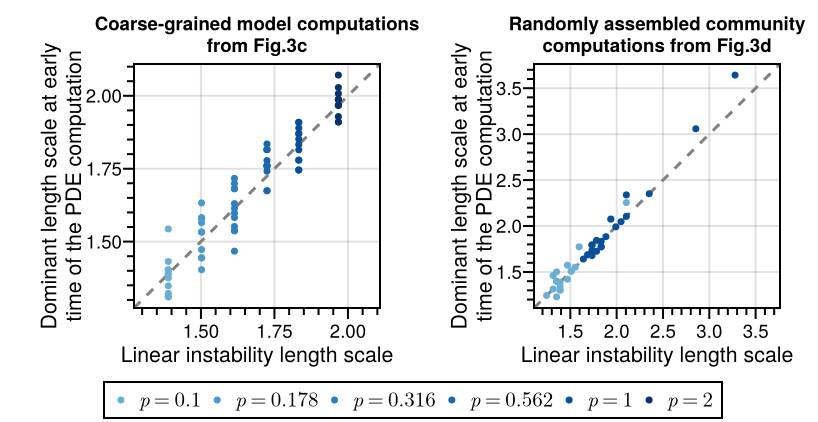

In [61]:
fig = Figure(;
    size=(double_col_width * 0.3 * 2, 0.50 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

ax1 = Axis(fig[1, 1];
    title="Coarse-grained model computations\nfrom Fig.3c",
    titlesize=7fontsize_pt,
    aspect=DataAspect(),
    # labels
    xlabel="Linear instability length scale",
    ylabel="Dominant length scale at early\ntime of the PDE computation",
    # ylabel="Length scale of the initial\ninstability in the PDE computation",
    # ylabel="Length scale of the dominant\nFFT mode at early times",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

ablines!(ax1, 0, 1; color=:gray, linestyle=:dash)
for r in eachrow(mmpdes_df)
    scatter!(ax1, r.linstab_l, r.et_l;
        markersize=5,
        color=PaperColors.p_color1(r.p)
    )
end

lo, hi = extrema([mmpdes_df.linstab_l; mmpdes_df.et_l])
pad = 0.05 * (hi - lo)
limits!(ax1, lo - pad, hi + pad, lo - pad, hi + pad)

ax2 = Axis(fig[1, 2];
    title="Randomly assembled community\ncomputations from Fig.3d",
    titlesize=7fontsize_pt,
    aspect=DataAspect(),
    # labels
    xlabel="Linear instability length scale",
    ylabel="Dominant length scale at early\ntime of the PDE computation",
    # ylabel="Length scale of the initial\ninstability in the PDE computation",
    # ylabel="Length scale of the dominant\nFFT mode at early times",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

ablines!(ax2, 0, 1; color=:gray, linestyle=:dash)
for r in eachrow(m8_df)
    scatter!(ax2, r.linstab_l, r.et_l;
        markersize=5,
        color=PaperColors.p_color1(r.p)
    )
end

lo, hi = extrema([m8_df.linstab_l; m8_df.et_l])
pad = 0.05 * (hi - lo)
limits!(ax2, lo - pad, hi + pad, lo - pad, hi + pad)

legend_ps = sort(unique(mmpdes_df.p))
Legend(fig[2,:],
    [
        [MarkerElement(; color=PaperColors.p_color1(p), marker=:circle, markersize=5) for p in legend_ps];
        # LineElement(; color=:gray, linestyle=:dash)
    ],
    [
        [latexstring(@sprintf("p = %.3g", p)) for p in legend_ps];
        # L"y = x"
    ];
    orientation=:horizontal,
    labelsize=7fontsize_ltex_pt,
    # framevisible=false,
    backgroundcolor=:transparent,
    patchsize=(8., 6.),
    patchlabelgap=5.,
    rowgap=0.,
    colgap=4.,
    padding=(4., 4., 4., 4.),
    alignmode=Mixed(left=-44),
    tellwidth=true,
)

# colsize!(fig.layout, 0, Fixed(0))
colgap!(fig.layout, 0.)
rowgap!(fig.layout, 8.)

Makie.save("../../figures2/si_extras/early_time_length_scales.pdf", fig)

fig

## MM data (more systems but less impressive)

In [7]:
mmpdes_df.linstab_l = 2pi ./ mmpdes_df.peak_k;
mmpdes_df.et_l = map(mmpdes_df.early_time_modes) do etm etm.lengthscale end;

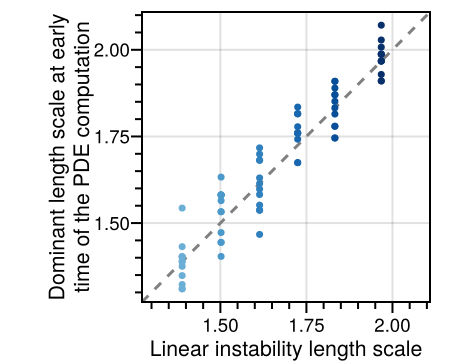

In [101]:
fig = Figure(;
    size=(double_col_width * 0.35, 0.43 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

ax = Axis(fig[1, 1];
    aspect=DataAspect(),
    # labels
    xlabel="Linear instability length scale",
    ylabel="Dominant length scale at early\ntime of the PDE computation",
    # ylabel="Length scale of the initial\ninstability in the PDE computation",
    # ylabel="Length scale of the dominant\nFFT mode at early times",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

ablines!(ax, 0, 1; color=:gray, linestyle=:dash)
for r in eachrow(mmpdes_df)
    scatter!(ax, r.linstab_l, r.et_l;
        markersize=5,
        color=PaperColors.p_color1(r.p)
    )
end

lo, hi = extrema([mmpdes_df.linstab_l; mmpdes_df.et_l])
pad = 0.05 * (hi - lo)
limits!(ax, lo - pad, hi + pad, lo - pad, hi + pad)

Makie.save("../../figures2/si_extras/mm_early_time_length_scales.pdf", fig)

fig

## SI data (from Fig. 3d, 20 systems at 2 ps with 100 peaks)

In [95]:
m8_df.ts = Vector{Vector{Float64}}(undef, nrow(m8_df))
m8_df.Bxt = Vector{Vector{Vector{Float64}}}(undef, nrow(m8_df))
@showprogress for (j, r) in enumerate(eachrow(m8_df))
    (; ts, us) = load_pde_states(joinpath(m8dir, "data"), r.pde_df_row)
    m8_df.ts[j] = ts
    # biomass summed over strains, Bxt[k] is the spatial profile at ts[k]
    m8_df.Bxt[j] = [vec(sum(u[1:r.Ns, :]; dims=1)) for u in us]
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:06

In [96]:
m8_df.early_time_modes = map(eachrow(m8_df)) do r
    first_strong_mode(r.Bxt, r.L)
end;
count(isnothing, m8_df.early_time_modes)

0

In [97]:
m8_df.linstab_l = m8_df.L ./ m8_smd.num_peaks;
m8_df.et_l = map(m8_df.early_time_modes) do etm etm.lengthscale end;

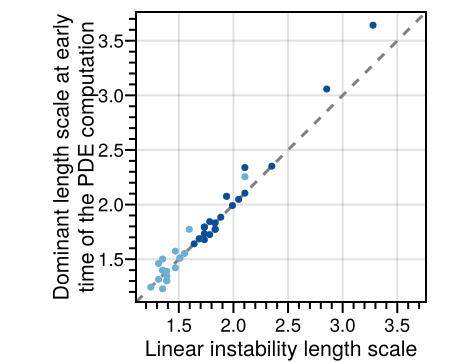

In [100]:
fig = Figure(;
    size=(double_col_width * 0.35, 0.43 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

ax = Axis(fig[1, 1];
    aspect=DataAspect(),
    # labels
    xlabel="Linear instability length scale",
    ylabel="Dominant length scale at early\ntime of the PDE computation",
    # ylabel="Length scale of the initial\ninstability in the PDE computation",
    # ylabel="Length scale of the dominant\nFFT mode at early times",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

ablines!(ax, 0, 1; color=:gray, linestyle=:dash)
for r in eachrow(m8_df)
    scatter!(ax, r.linstab_l, r.et_l;
        markersize=5,
        color=PaperColors.p_color1(r.p)
    )
end

lo, hi = extrema([m8_df.linstab_l; m8_df.et_l])
pad = 0.05 * (hi - lo)
limits!(ax, lo - pad, hi + pad, lo - pad, hi + pad)

Makie.save("../../figures2/si_extras/si_early_time_length_scales.pdf", fig)

fig

# HSS vs average PDE fs abundances

## Fig. 3e dataset

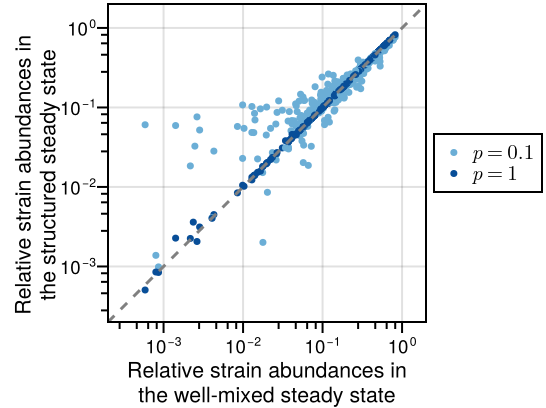

In [111]:
fig = Figure(;
    size=(double_col_width * 0.4, double_col_width * 0.3),
    figure_padding=(2., 2., 2., 2.),
)

ax = Axis(fig[1, 1];
    aspect=DataAspect(),
    # labels
    xlabel="Relative strain abundances in\nthe well-mixed steady state",
    ylabel="Relative strain abundances in    \nthe structured steady state    ",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xscale=log10,
    yscale=log10,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)


xx = @subset m9_df :p .>= 0.1
for r in eachrow(xx)
    rhss = r.so_hss ./ sum(r.so_hss)
    rfs = r.so_fs ./ sum(r.so_fs)
    scatter!(ax, rhss, rfs;
        markersize=5,
        color=PaperColors.p_color1(r.p)
    )
end

lo = 2e-4
hi = 2
lines!(ax, [lo, hi], [lo, hi]; color=:gray, linestyle=:dash)
xlims!(ax, lo, hi)
ylims!(ax, lo, hi)

legend_ps = sort(unique(xx.p))
Legend(fig[1,2],
    [MarkerElement(; color=PaperColors.p_color1(p), marker=:circle, markersize=5) for p in legend_ps],
    [latexstring(@sprintf("p = %.3g", p)) for p in legend_ps];
    labelsize=7fontsize_ltex_pt,
    backgroundcolor=:transparent,
    patchsize=(12., 6.),
    patchlabelgap=3.,
    rowgap=0.,
    padding=(4., 4., 4., 4.),
)

colgap!(fig.layout, 0.)

Makie.save("../../figures2/si_extras/rel_abundance_change_m9.pdf", fig)

fig

# Biomass changes in single peak data

count((p->begin
            #= In[18]:8 =#
            p in ps
        end), m9_df.p) = 196
nrow(m9_df) = 296

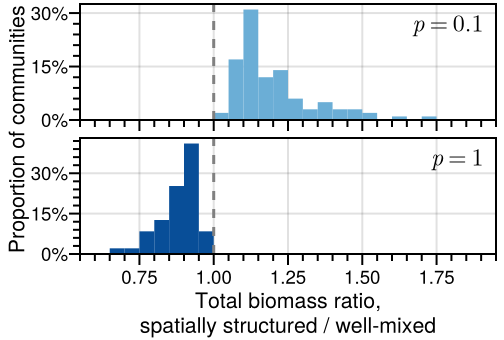

In [18]:
fig = Figure(;
    size=(double_col_width * 0.37, double_col_width * 0.25),
    figure_padding=(2., 4., 2., 2.),
)

bins = range(0.55, 1.95; step=0.05)
ps = [0.1, 1.]
@show count(p->p in ps, m9_df.p) nrow(m9_df)
axs = map(enumerate(ps)) do (i, p)
    ax = Axis(fig[i, 1];
        xlabel="Total biomass ratio,\nspatially structured / well-mixed",
        xlabelsize=8fontsize_pt,
        xlabelpadding=0.,
        xticklabelsize=7fontsize_pt,
        yticklabelsize=7fontsize_pt,
        xticklabelpad=0.,
        yticklabelpad=0.,
        xminorticksvisible=true,
        xminorticks=IntervalsBetween(5),
        yminorticksvisible=true,
        yminorticks=IntervalsBetween(5),
        yticks=([0., 0.15, 0.3], ["0%", "15%", "30%"]),
    )
    d = @subset m9_df :p .== p
    hist!(ax, sum.(d.so_fs) ./ sum.(d.so_hss);
        bins,
        normalization=:probability,
        color=PaperColors.p_color1(p),
    )
    vlines!(ax, 1.; color=:gray, linestyle=:dash)
    text!(ax, 0.97, 0.93;
        text=latexstring(@sprintf("p = %.3g", p)),
        space=:relative,
        align=(:right, :top),
        fontsize=8fontsize_ltex_pt,
    )
    ylims!(ax, 0, nothing)
    ax
end
linkxaxes!(axs...)
xlims!(axs[2], first(bins), last(bins))
hidexdecorations!(axs[1]; ticks=false, minorticks=false, grid=false, minorgrid=false)

Label(fig[:, 0], "Proportion of communities"; rotation=pi/2, fontsize=8fontsize_pt)
rowgap!(fig.layout, 4.)
colgap!(fig.layout, 2.)

Makie.save("../../figures2/si_extras/one_peak_totbiom_ratio_hist.pdf", fig)

fig

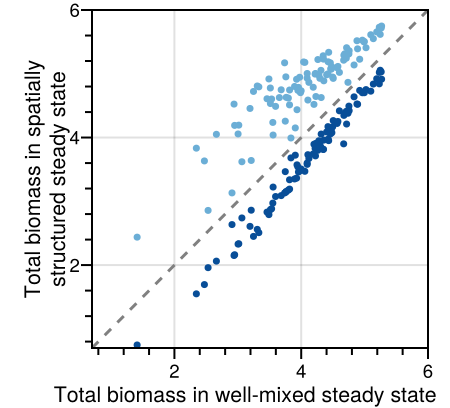

In [141]:
fig = Figure(;
    size=(double_col_width * 0.33, double_col_width * 0.3),
    figure_padding=(2., 2., 2., 5.),
)

ax = Axis(fig[1, 1];
    aspect=DataAspect(),
    # labels
    xlabel="Total biomass in well-mixed steady state     ",
    ylabel="Total biomass in spatially\nstructured steady state",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    xlabelpadding=0.,
    ylabelpadding=0.,
    # ticks style
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    # xscale=log10,
    # yscale=log10,
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(5),
    yminorticksvisible=true,
    yminorticks=IntervalsBetween(5),
)

lo = 0.7
hi = 6
lines!(ax, [lo, hi], [lo, hi]; color=:gray, linestyle=:dash)
xlims!(ax, lo, hi)
ylims!(ax, lo, hi)


scatter!(ax, sum.(xx.so_hss), sum.(xx.so_fs);
    markersize=5,
    color=PaperColors.p_color1.(xx.p),
)
# ablines!(ax, 0, 1; color=:gray, linestyle=:dash)

Makie.save("../../figures2/si_extras/one_peak_totbiom_change.pdf", fig)

fig

# Example peak structure

In [20]:
m8_df.series_t = Vector{Vector{Float64}}(undef, nrow(m8_df))
m8_df.series_N = Vector{Vector{Vector{Float64}}}(undef, nrow(m8_df))
m8_df.series_I = Vector{Vector{Vector{Float64}}}(undef, nrow(m8_df))
m8_df.series_R = Vector{Vector{Vector{Float64}}}(undef, nrow(m8_df))

@showprogress for i in 1:nrow(m8_df)
    p = m8_setup_df.params[m8_df.pde_df_row[i]]
    Ns = m8_df.Ns[i]
    nr = size(p.c, 2)

    # influx resource, and the other resources some strain consumes
    j0 = findfirst(K -> K > 0, p.K)
    crossfed = Int[]
    for j in 1:nr
        if j != j0 && any(p.c[:, j] .> 0)
            push!(crossfed, j)
        end
    end

    ts, us = load_pde_states(joinpath(m8dir, "data"), m8_df.pde_df_row[i])
    N = Vector{Float64}[]
    I = Vector{Float64}[]
    R = Vector{Float64}[]
    for u in us
        push!(N, vec(sum(u[1:Ns, :]; dims=1)))
        push!(I, u[Ns+j0, :])
        push!(R, vec(sum(u[Ns .+ crossfed, :]; dims=1)))
    end

    m8_df.series_t[i] = ts
    m8_df.series_N[i] = N
    m8_df.series_I[i] = I
    m8_df.series_R[i] = R
    us = nothing
    GC.gc()
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:18

r1.T = 1.0e8

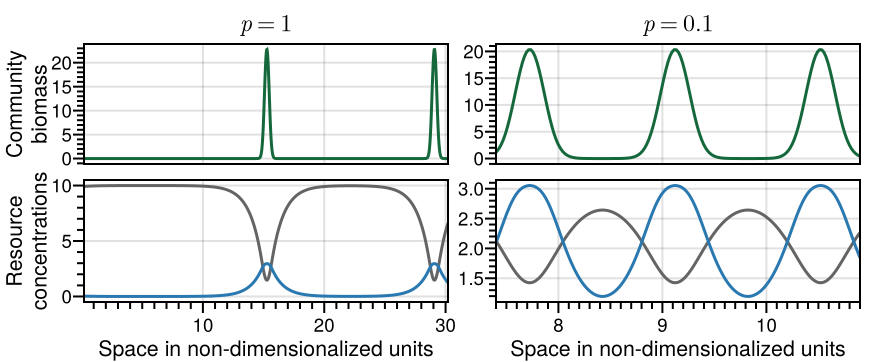

In [23]:
r1 = m8_df[2,:]
r2 = m8_df[1,:];
@assert r1.df_row == r2.df_row
@assert r1.series_t[end] == r2.series_t[end] == r1.T
@show r1.T

fig = Figure(;
    size=(double_col_width * 0.64, 0.43 * double_col_width / golden_ratio),
    figure_padding=(2., 6., 2., 6.),
)

axs = []
for (ri, r) in enumerate([r1, r2])
    ax1, ax2 = map([1, 2]) do i
        Axis(fig[i, ri];
            # labels
            titlesize=8fontsize_ltex_pt,
            xlabel="Space in non-dimensionalized units",
            xlabelsize=8fontsize_pt,
            ylabelsize=8fontsize_pt,
            xlabelpadding=0.,
            ylabelpadding=0.,
            # ticks style
            xticklabelsize=7fontsize_pt,
            yticklabelsize=7fontsize_pt,
            xticklabelpad=0.,
            yticklabelpad=0.,
            # setup log scale ticks with minors
            xminorticksvisible=true,
            xminorticks=IntervalsBetween(10),
            yminorticksvisible=true,
            yminorticks=IntervalsBetween(5),
        )
    end
    linkxaxes!(ax1, ax2)
    hidexdecorations!(ax1; grid=false)
    ax1.title = latexstring(@sprintf "p=%.3g" r.p)
    
    xs = ((1:r.sN) .- 0.5) .* (r.L / r.sN)

    lines!(ax1, xs, r.series_N[end]; color=colorant"#15683b")
    lines!(ax2, xs, r.series_I[end]; color=colorant"#646464")
    lines!(ax2, xs, r.series_R[end]; color=colorant"#2978b0")

    xlims!(ax2, extrema(xs)...)

    append!(axs, [ax1, ax2])
end

axs[1].ylabel = "Community\nbiomass"
axs[2].ylabel = "Resource\nconcentrations"

xlims!(axs[2], 0.2, 30.2)
xlims!(axs[4], 7.4, 10.9)

rowgap!(fig.layout, 8.)
colgap!(fig.layout, 6.)

Makie.save("../../figures2/si_extras/pde_fs_samples.pdf", fig)

fig